# Exploratory analysis - London smart-meter data (and synthetic comparison)

This notebook explores the **cleaned, sampled real data** produced by `scripts/download_data.py` and the processed outputs of `scripts/run_pipeline.py`. It checks the assumptions used in the methodology: UTC timestamps, coverage, zero readings, seasonality and load shapes.

Run it from the project root after the pipeline. If the real data is missing, the real-data cells say so and the synthetic cells still run.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from electricity_anomaly.config import load_config, get_windows
from electricity_anomaly.preprocessing import preprocess
cfg = load_config(ROOT / "config" / "config.yaml")
windows = get_windows(cfg)
REAL_CACHE = ROOT / "data" / "processed" / cfg["real"]["cache_name"]
print("real cache available:", REAL_CACHE.exists())

real cache available: True


## 1. Cleaned real readings and preprocessing counts

In [2]:
if REAL_CACHE.exists():
    meta = json.loads(REAL_CACHE.with_suffix('.meta.json').read_text())
    display(pd.Series(meta['stats'], name='count').to_frame())
    clean = pd.read_parquet(REAL_CACHE)
    print(f"{len(clean):,} clean readings, {clean['customer_id'].nunique()} households")
else:
    clean = None
    print('Real data not prepared - run: python scripts/download_data.py')

,count
raw_rows_scanned,167932474
rows_other_tariff,33783771
rows_not_in_household_sample,100834983
rows_read,33313720
rows_missing_customer_id,0
rows_malformed_timestamp,0
rows_missing_reading,1100
rows_non_numeric_reading,0
rows_negative_reading,0
rows_implausible_reading,0


18,611,205 clean readings, 1094 households


## 2. Are the source timestamps UTC? (readings per calendar day around DST)
A local-time record would have 46 readings on 2013-03-31 and 50 on 2013-10-27. UTC gives 48 every day.

In [3]:
if clean is not None:
    d = clean.assign(date=clean['timestamp'].dt.normalize())
    for day in ['2013-03-30', '2013-03-31', '2013-10-27']:
        counts = d.loc[d['date'] == day].groupby('customer_id', observed=True).size()
        print(day, counts.value_counts().head(3).to_dict())

2013-03-30 {48: 1076, 46: 1, 47: 1}
2013-03-31 {48: 1077, 1: 1}
2013-10-27 {49: 1029, 2: 2, 47: 2}


## 3. Coverage, zeros and daily consumption

eligible households: 1012 of 1094


households with >50% zero readings: 6


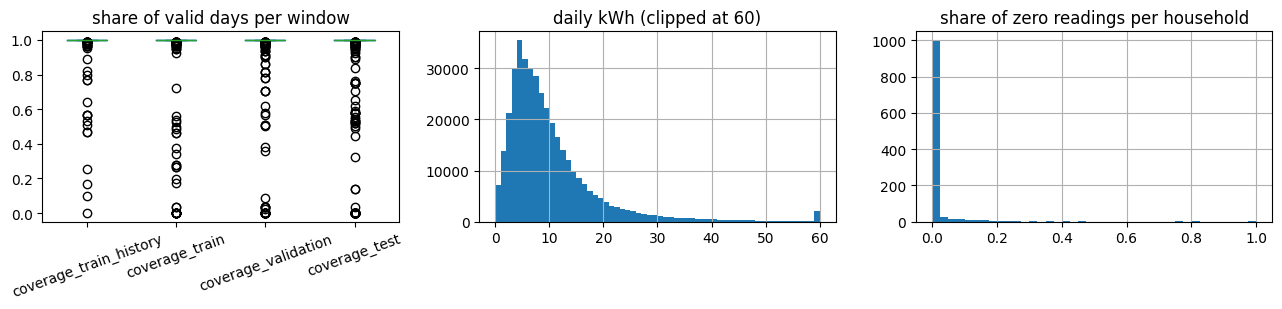

In [4]:
if clean is not None:
    data = preprocess(clean, cfg, windows)
    daily = data.daily
    print('eligible households:', data.stats['customers_eligible'], 'of', data.stats['customers_in_study_period'])
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
    data.coverage[[c for c in data.coverage if c.startswith('coverage_')]].plot.box(ax=ax[0], rot=20); ax[0].set_title('share of valid days per window')
    daily.loc[daily['valid'], 'daily_kwh'].clip(upper=60).hist(bins=60, ax=ax[1]); ax[1].set_title('daily kWh (clipped at 60)')
    zero_share = (clean['kwh'] == 0).groupby(clean['customer_id'], observed=True).mean()
    zero_share.hist(bins=40, ax=ax[2]); ax[2].set_title('share of zero readings per household')
    plt.tight_layout()
    print('households with >50% zero readings:', int((zero_share > 0.5).sum()))

## 4. Seasonality: why population alignment is needed
The median household's consumption changes by season. A model trained on Q2 would rate everyone as anomalous in Q4 unless window-wide shifts are removed.

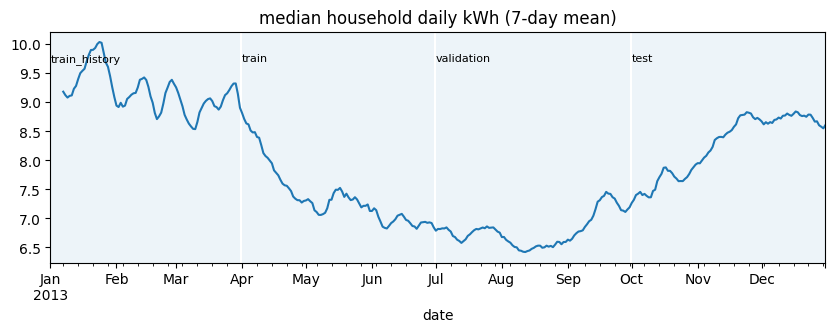

In [5]:
if clean is not None:
    med = daily.loc[daily['valid']].groupby(level='date')['daily_kwh'].median()
    ax = med.rolling(7).mean().plot(figsize=(10, 3), title='median household daily kWh (7-day mean)')
    for name, (a, b) in windows.items():
        ax.axvspan(a, b, alpha=0.08); ax.text(a, ax.get_ylim()[1] * 0.95, name, fontsize=8)

## 5. Average load shape (local time): weekday vs weekend

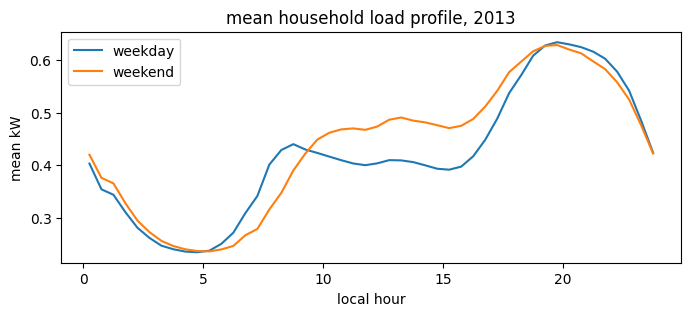

In [6]:
if clean is not None:
    m = data.slot_matrix
    wk = m.index.get_level_values('date').dayofweek >= 5
    hours = (np.arange(48) + 0.5) / 2
    plt.figure(figsize=(8, 3))
    plt.plot(hours, m[~wk].mean().to_numpy() * 2, label='weekday'); plt.plot(hours, m[wk].mean().to_numpy() * 2, label='weekend')
    plt.xlabel('local hour'); plt.ylabel('mean kW'); plt.legend(); plt.title('mean household load profile, 2013')

## 6. Synthetic data for comparison
The synthetic generator imitates these properties: archetype load shapes, seasonality, away periods and data defects.

In [7]:
syn = ROOT / 'outputs' / 'pipeline' / 'synthetic' / 'preprocessing_stats.json'
if syn.exists():
    display(pd.Series(json.loads(syn.read_text()), name='synthetic').to_frame())
else:
    print('Run: python scripts/run_pipeline.py --data synthetic')

,synthetic
raw_rows_scanned,3409328
rows_not_in_household_sample,0
rows_read,3409328
rows_missing_customer_id,0
rows_malformed_timestamp,5
rows_missing_reading,10163
rows_non_numeric_reading,0
rows_negative_reading,336
rows_implausible_reading,154
zero_readings_kept,0


## 7. Pipeline results on real data (unlabelled)
Rankings are signals for investigation. There are no labels, so no accuracy is computed.

In [8]:
res_p = ROOT / 'outputs' / 'pipeline' / 'real' / 'customer_results.csv'
if res_p.exists():
    res = pd.read_csv(res_p, index_col=0)
    display(res[['customer_anomaly_score', 'peer_deviation_score', 'observation_level_score', 'mean_daily_kwh',
                 'observation_anomaly_count', 'observation_longest_flag_run_days', 'principal_behavioural_deviations']].head(10))
    print(res[['customer_anomaly_score', 'observation_level_score', 'peer_deviation_score']].corr(method='spearman').round(2))

,customer_anomaly_score,peer_deviation_score,observation_level_score,mean_daily_kwh,observation_anomaly_count,observation_longest_flag_run_days,principal_behavioural_deviations
customer_id,,,,,,,
MAC002594,1.0000,20.000,0.9083,0.000,1,1,cv_daily (+20.0 peer-MAD); mean_abs_change_rel...
MAC000287,0.9967,15.782,1.0000,1.317,44,35,low_day_freq (+20.0 peer-MAD); trend_slope_rel...
MAC005393,0.9967,12.465,0.9917,19.759,21,3,half_split_change_log (+14.1 peer-MAD); night_...
MAC005344,0.9967,14.440,0.8617,24.683,0,0,low_day_freq (+20.0 peer-MAD); night_share_cha...
MAC000260,0.9950,15.816,1.0000,9.702,70,66,low_day_freq (+20.0 peer-MAD); profile_shape_d...
MAC004884,0.9933,13.511,1.0000,32.551,65,54,night_share_change (+19.8 peer-MAD); profile_s...
MAC000415,0.9933,14.291,0.9933,19.947,22,2,low_day_freq (+20.0 peer-MAD); night_share (+1...
MAC000654,0.9933,13.263,0.9700,33.096,7,2,low_day_freq (+20.0 peer-MAD); peak_change_log...
MAC004563,0.9933,9.766,0.9083,16.720,1,1,night_share_change (+14.5 peer-MAD); night_sha...


                         customer_anomaly_score  observation_level_score  \
customer_anomaly_score                     1.00                     0.41   
observation_level_score                    0.41                     1.00   
peer_deviation_score                       0.69                     0.48   

                         peer_deviation_score  
customer_anomaly_score                   0.69  
observation_level_score                  0.48  
peer_deviation_score                     1.00  
